In [1]:
import statsmodels.api as sm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
#import ssl; ssl._create_default_https_context = ssl._create_unverified_context
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

from sciRED import ensembleFCA as efca
from sciRED import glm
from sciRED import rotations as rot
from sciRED import metrics as met

from sciRED.utils import preprocess as proc
from sciRED.utils import visualize as vis
from sciRED.utils import corr

In [2]:
np.random.seed(10)
NUM_COMPONENTS = 50

In [3]:
data_file_path = '/Users/jonathanalgoo/Desktop/hypothalamus_project_analysis/Code to produce Figures/microglia and astrocyte vignette/microglia.h5ad'
data = sc.read_h5ad(data_file_path)
y, genes, num_cells, num_genes = proc.get_data_array(data)
#Get pearson residuals


23959 3000


In [4]:
#### design matrix - library size only
x = proc.get_library_design_mat(data, lib_size='nUMIs')
#x = sm.add_constant(x) # Adds a column of 1s to the design matrix; don't use in tutorial only regressing UMIs so won't do her
### fit GLM to each gene
glm_fit_dict = glm.poissonGLM(y, x)
resid_pearson = glm_fit_dict['resid_pearson'] 
print('pearson residuals: ', resid_pearson.shape) # numpy array of shape (num_genes, num_cells)
print('y shape: ', y.shape) # (num_cells, num_genes)
y = resid_pearson.T # (num_cells, num_genes)
print('y shape: ', y.shape) # (num_cells, num_genes)

time to fit the model:  40.59109807014465
pearson residuals:  (3000, 23959)
y shape:  (23959, 3000)
y shape:  (23959, 3000)


In [5]:
glm_fit_dict

{'resid_pearson': array([[-0.51018379, -1.20616309,  0.46071615, ...,  0.23183577,
         -1.20373757,  0.07308942],
        [-0.0589596 , -0.05783201, -0.05777966, ..., -0.05917549,
         -0.05779741, -0.06016948],
        [-0.36544938, -0.30921446, -0.30680067, ...,  2.27397556,
         -0.30761751,  1.85961272],
        ...,
        [-0.47434258, -0.43081909, -0.42887883, ..., -0.48306266,
         -0.42953615, -0.52487955],
        [-0.44491064, -1.1585838 ,  0.57760455, ..., -0.47344405,
         -1.15594934,  0.13762005],
        [-0.03634754, -0.02873384, -0.02841881, ..., -0.03800116,
         -0.02852531, -0.04654328]], shape=(3000, 23959)),
 'resid_deviance': array([[-0.55110535, -1.7057722 ,  0.43519035, ...,  0.22542563,
         -1.70234199,  0.07245724],
        [-0.08338146, -0.08178681, -0.08171277, ..., -0.08368678,
         -0.08173789, -0.08509249],
        [-0.51682348, -0.43729529, -0.43388166, ...,  1.47802197,
         -0.43503686,  1.30501299],
        ...

PCA step

In [6]:
####################################
#### Running PCA on the data ######
####################################
### using pipeline to scale the data first
pipeline = Pipeline([('scaling', StandardScaler()), ('pca', PCA(n_components=NUM_COMPONENTS))])
pca_scores = pipeline.fit_transform(y)
pca = pipeline.named_steps['pca']
pca_loading = pca.components_ 
pca_loading.shape #(factors, genes)



(50, 3000)

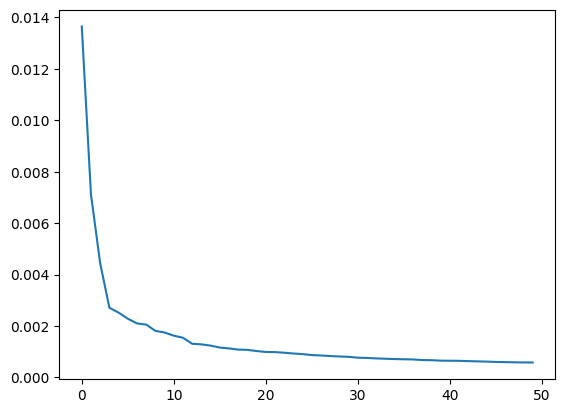

In [7]:
plt.plot(pca.explained_variance_ratio_)

In [8]:
######## Applying varimax rotation to the factor scores
rotation_results_varimax = rot.varimax(pca_loading.T)
varimax_loading = rotation_results_varimax['rotloading']
pca_scores_varimax = rot.get_rotated_scores(pca_scores, rotation_results_varimax['rotmat'])


In [9]:
##### Setting the factor scores an loadings to be used in step-2 based on Varimax factors
factor_loading = rotation_results_varimax['rotloading']
factor_scores = pca_scores_varimax

In [10]:
#convert to pandas df, add colnames and rownames, and write to csv (scired_loadings_per_gene.csv, scired_scores_per_cell.csv)

In [11]:
# 1. Create DataFrame for loadings (Genes x Factors)
# Uses data.var.gene for index as specified
loadings_df = pd.DataFrame(
    factor_loading, 
    index=data.var['gene'], 
    columns=[f'Factor_{i+1}' for i in range(NUM_COMPONENTS)]
)

# 2. Create DataFrame for scores (Cells x Factors)
# Uses data.obs.cell_id for index as specified
scores_df = pd.DataFrame(
    factor_scores, 
    index=data.obs['cell_id'], 
    columns=[f'Factor_{i+1}' for i in range(NUM_COMPONENTS)]
)

# 3. Write to CSV
loadings_df.to_csv('scired_loadings_per_gene.csv')
scores_df.to_csv('scired_scores_per_cell.csv')

In [12]:
varimax_loading_df = pd.DataFrame(varimax_loading)
varimax_loading_df.columns = ['F'+str(i) for i in range(1, varimax_loading_df.shape[1]+1)]
varimax_loading_df.index = genes
pca_scores_varimax_df = pd.DataFrame(pca_scores_varimax)
pca_scores_varimax_df.columns = ['F'+str(i) for i in range(1, pca_scores_varimax_df.shape[1]+1)]
pca_scores_varimax_df.index = data.obs['cell_id']

